In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

In [3]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp

import acoustic_inversion as ai 

In [4]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [5]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.6

In [6]:
data1 = scipy.io.loadmat("../data/field_values20260707/field_values20260707.mat")


f = data1['f'].squeeze()
f_Vg = f[1:-1]
c = data1['soundspeed'].squeeze()
Vg = data1['Vg'].squeeze().transpose([1,0,2])
rho = data1['rho'].squeeze()
receiver_range = data1['range'][0,0]

In [7]:
Vg.shape

(29, 17, 299)

In [8]:
arrival_times_data = receiver_range/Vg[c == TRUE_SOUNDSPEED, ...].squeeze()
arrival_times_replica = receiver_range/Vg

In [9]:
lk = ai.AcousticInversionLikelihood(arrival_times_data)

In [10]:
likelihood = lk.likelihood(arrival_times_replica)

#likelihood = likelihood/likelihood.sum()

In [11]:
cmax = np.unravel_index(np.argmax(likelihood), likelihood.shape)

In [12]:
deltas_intramode = ai.calculate_deltas(arrival_times_replica)
deltas_intermode = ai.calculate_deltas(arrival_times_replica.mT)

In [13]:
fisher_info_intramode = np.sum((np.diff(deltas_intramode, axis=0).T/np.diff(c))**2, axis=-1).T
fisher_info_intermode = np.sum((np.diff(deltas_intermode, axis=0).T/np.diff(c))**2, axis=-1).T

In [23]:
fisher_info_direct = np.sum((np.diff(arrival_times_replica, axis=0).T/np.diff(c))**2, axis=(-3,-1)).T

In [26]:
np.argsort(fisher_info_direct)

array([ 5,  4,  6,  3,  2,  1,  7,  8,  9, 13, 12, 10, 11, 14, 15, 16,  0])

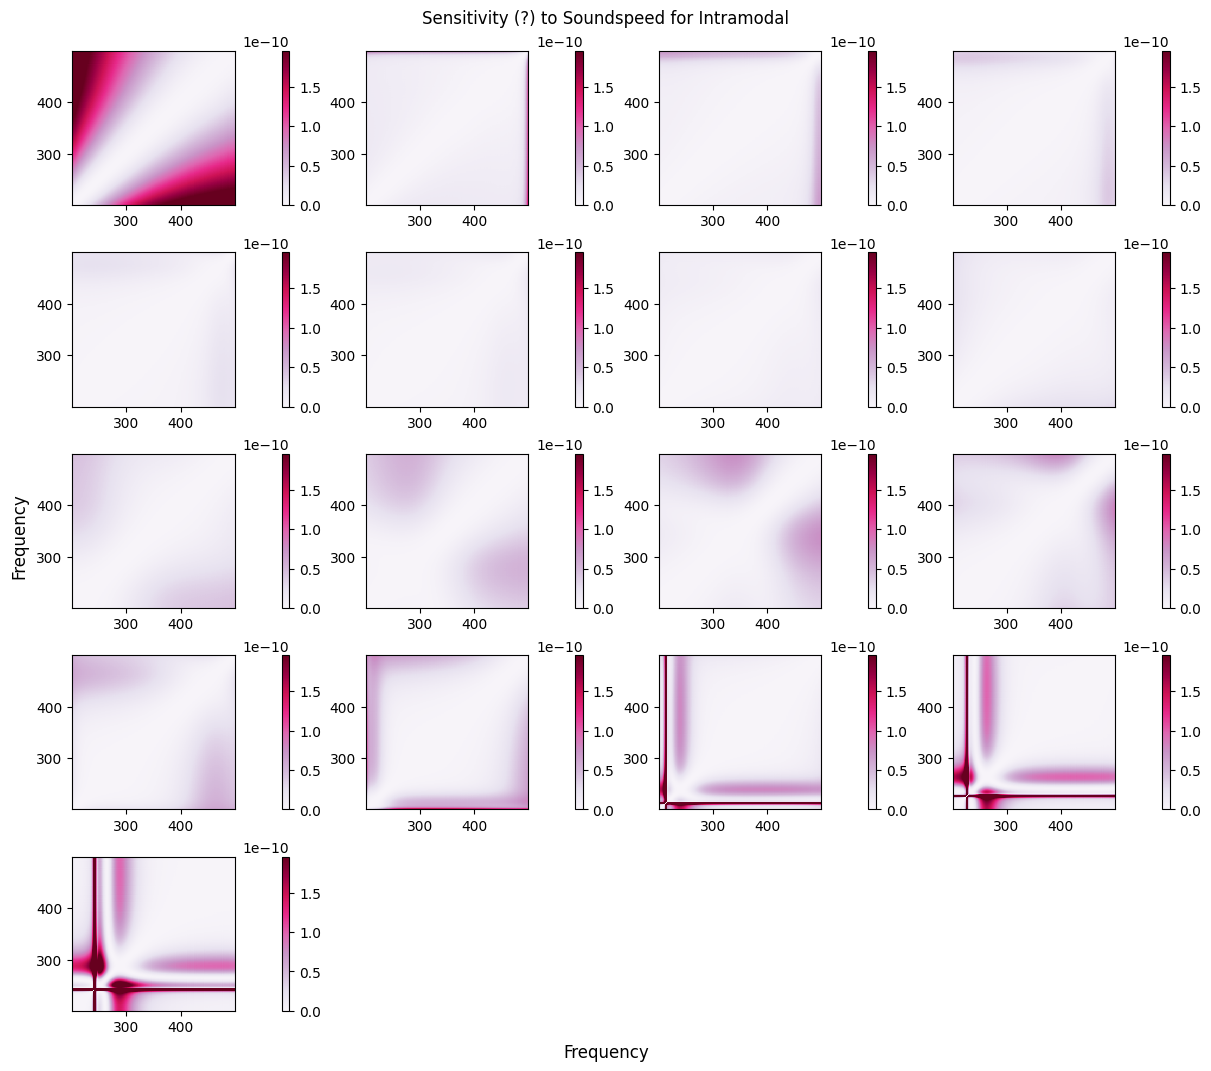

In [45]:
fig = plt.figure(layout = "constrained")

diff_intra = diff_intra/diff_intra.max()

vmin, vmax = np.quantile(fisher_info_intramode, [0,.99])

for ind, X in enumerate(fisher_info_intramode):
    ax = fig.add_subplot(5,4,ind+1)
    m = ax.pcolormesh(f_Vg, f_Vg, X, cmap="PuRd", vmin=vmin, vmax=vmax)
    plt.colorbar(m, ax=ax)

fig.suptitle('Sensitivity (?) to Soundspeed for Intramodal')
fig.supxlabel('Frequency')
fig.supylabel('Frequency')

fig.set_size_inches([12,10.6])

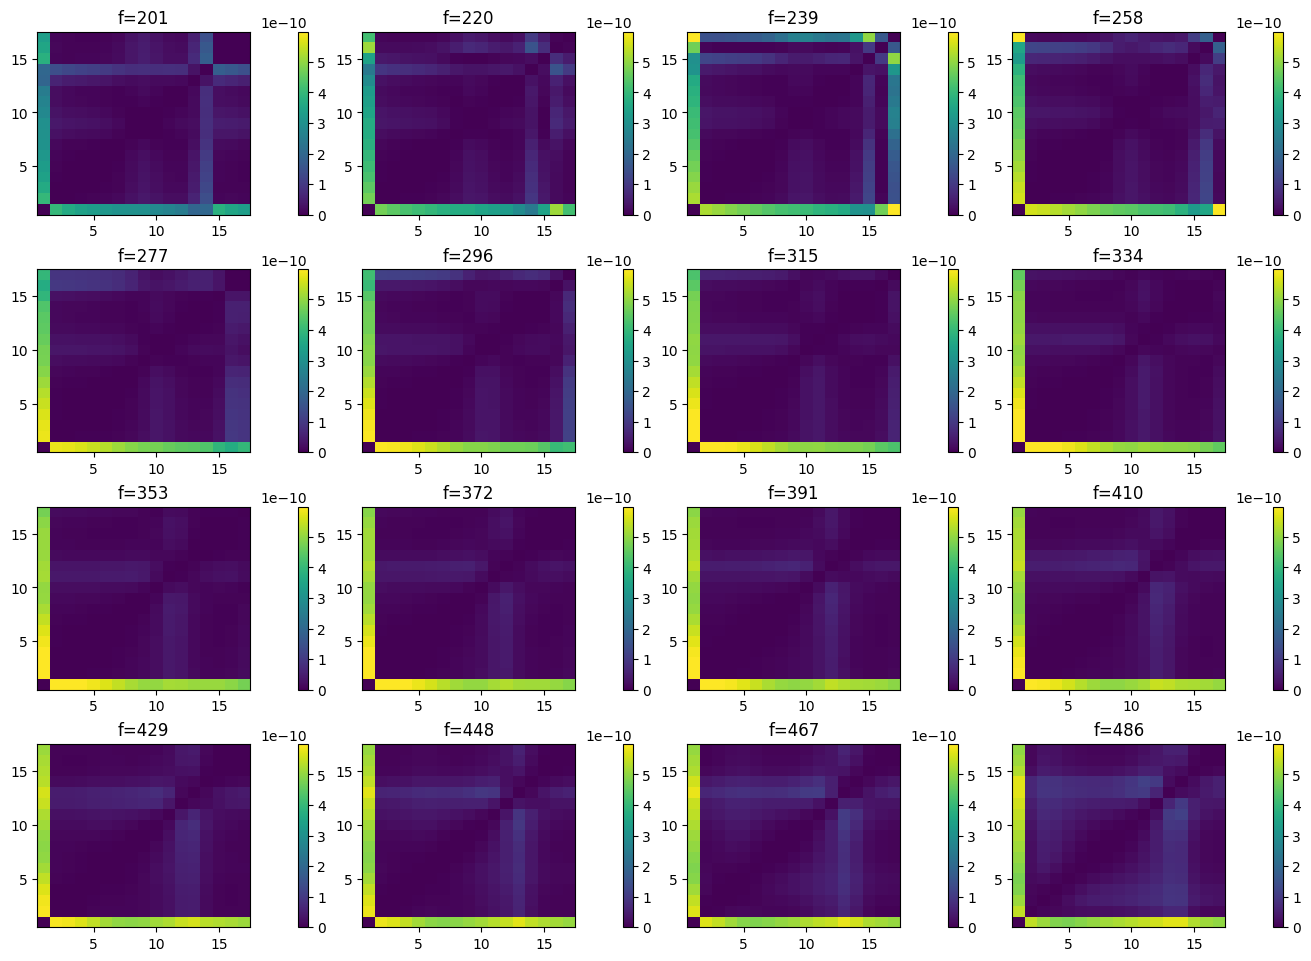

In [48]:
fig, ax = plt.subplots(4,4, layout = "constrained")

vmin, vmax = np.quantile(fisher_info_intermode, [0,.99])

for ind, indf in enumerate(np.arange(0,len(f_Vg),len(f_Vg)//15)):
    ax_ind = np.unravel_index(ind, ax.shape)

    m = ax[ax_ind].pcolormesh(np.arange(1,18),np.arange(1,18), fisher_info_intermode[indf], vmin=vmin, vmax=vmax)
    ax[ax_ind].set_title(f"f={f_Vg[indf]}")
    
    plt.colorbar(m, ax=ax[ax_ind])

fig.set_size_inches([13,9.5])

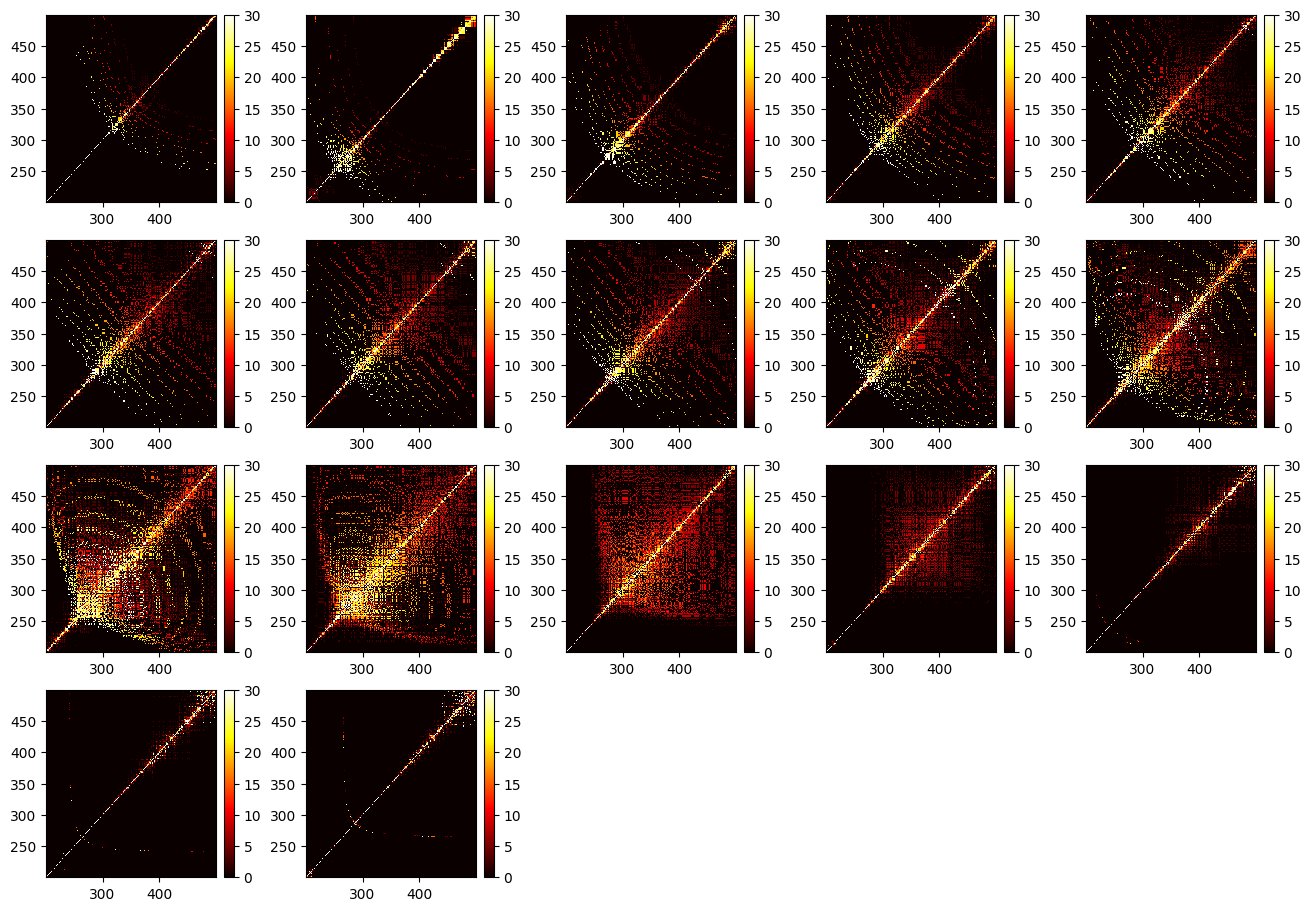

In [212]:
fig = plt.figure(layout = "constrained")

for ind, X in enumerate(eps):
    #ax_ind = np.unravel_index(ind, ax.shape)

    ax = fig.add_subplot(4,5,ind+1)
    
    m1 = ax.pcolormesh(f_Vg, f_Vg, X, cmap="hot")

    plt.colorbar(m1, ax=ax)

fig.set_size_inches([13,9])

In [204]:
trials = 2000

selected = [np.arange(15)[np.random.binomial(1, .5, 15) ==1] for n in range(ntrials)]

perturb = np.random.randint(0, 3, ntrials)

mode_labels = [s +p for s,p in zip(selected, perturb)]

In [205]:
hasmode1 = np.array([np.any(s==0) for s in selected]) 
hasmode1correct = np.all([hasmode1, perturb==0], 0)

In [206]:
normalize01 = lambda x: x/x.sum()
var = lambda p,x: np.sum(p*x**2) - np.sum(p*x)**2

In [237]:
likelihood_mc = np.empty((ntrials, len(c)))
var_mc = np.empty(ntrials)
for trial in range(ntrials):
    atimes_data = arrival_times_data[selected[trial]]
    atimes_replica = arrival_times_replica[:, mode_labels[trial]]
    #atimes_data = atimes_data + np.random.normal(size=atimes_data.shape)*.001
    lk_mc = ai.AcousticInversionLikelihood(atimes_data)
    likelihood_mc[trial] = normalize01(lk_mc.likelihood(atimes_replica, 5e-3))
    var_mc[trial] = var(likelihood_mc[trial], c)
    

In [238]:
var_unpert = var_mc[perturb == 0]
var_pert = var_mc[perturb != 0]

In [239]:
c[np.argmax(likelihood_mc[perturb==1], axis=1)]

array([1475. , 1432.5, 1430. , 1437.5, 1435. , 1432.5, 1432.5, 1430. ,
       1430. , 1432.5, 1430. , 1432.5, 1430. , 1430. , 1430. , 1440. ,
       1430. , 1430. , 1500. , 1432.5, 1435. , 1430. , 1430. , 1432.5,
       1430. , 1430. , 1437.5, 1430. , 1437.5, 1445. , 1435. , 1435. ,
       1430. , 1477.5, 1430. , 1430. , 1430. , 1430. , 1467.5, 1430. ,
       1430. , 1430. , 1430. , 1435. , 1430. , 1430. , 1430. , 1430. ,
       1430. , 1430. , 1430. , 1430. , 1430. , 1430. , 1440. , 1430. ,
       1487.5, 1430. , 1430. , 1430. , 1432.5, 1430. , 1437.5, 1435. ,
       1430. , 1430. , 1437.5, 1442.5, 1430. , 1430. , 1430. , 1430. ,
       1430. , 1430. , 1430. , 1480. , 1430. , 1437.5, 1437.5, 1430. ,
       1445. , 1500. , 1432.5, 1430. , 1475. , 1432.5, 1430. , 1432.5,
       1430. , 1430. , 1442.5, 1430. , 1430. , 1430. , 1475. , 1430. ,
       1500. , 1430. , 1432.5, 1430. , 1430. , 1430. , 1430. , 1430. ,
       1430. , 1477.5, 1430. , 1430. , 1430. , 1430. , 1432.5, 1435. ,
      

{'whiskers': [<matplotlib.lines.Line2D at 0x115e8d400>,
 'caps': [<matplotlib.lines.Line2D at 0x115e8d6a0>,
 'boxes': [<matplotlib.lines.Line2D at 0x115e8d2b0>,
 'medians': [<matplotlib.lines.Line2D at 0x115e8d940>,
 'fliers': [<matplotlib.lines.Line2D at 0x115e8da90>,
 'means': []}

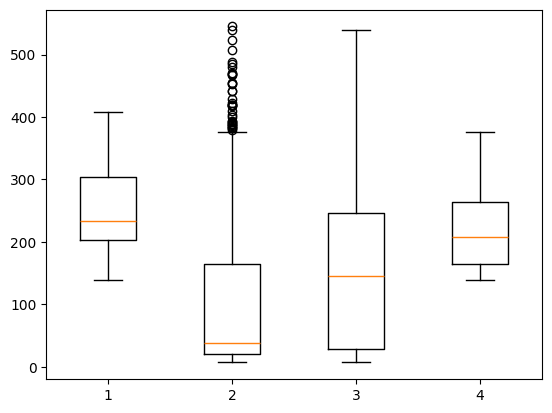

In [240]:
plt.boxplot([var_unpert, var_pert, var_mc[hasmode1], var_mc[hasmode1correct]])

In [126]:
lk_unpert = normalize01(likelihood_mc[perturb == 0])
lk_pert = normalize01(likelihood_mc[perturb != 0])

In [128]:
np.mean(c[np.argmax(lk_pert, 1)])

np.float64(1449.0561224489795)

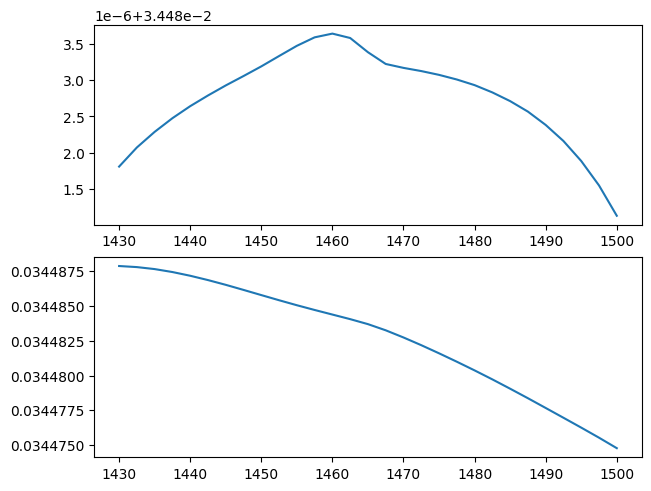

In [118]:
fig, ax = plt.subplots(2,1, layout="constrained")

ax[0].plot(c, lk_unpert)
ax[1].plot(c, lk_pert)

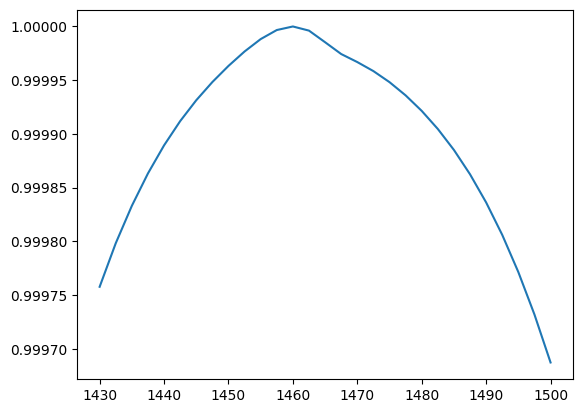

In [182]:
plt.plot(c, likelihood)